# Checking the Run Logs

In [1]:
import datetime as datetime

import pandas as pd
import numpy as np
import h5py as h5

import scipy
import matplotlib as mpl
import matplotlib.pyplot as plt

# boundary values
# semi major axis a
a_min = 2.0
a_max = 4.0
# eccentricity e
e_min = 0.0
e_max = 0.5
# inclination i
i_min = 0.0
i_max = 0.8


A = 6
E = 7
I = 8


In [28]:
particles_assigned = pd.read_hdf('../asteroid_data/sim_data/mc_3/inputs/clone_assignments.h5')

run_log = h5.File('../asteroid_data/sim_data/mc_3/results/pvals_20230501_1701_00000.h5',"r")

print(f"Sim number:{run_log.attrs['simulation']} Years modelled:{run_log.attrs['int_length']:0.1e} Walltime:{datetime.timedelta(seconds=run_log.attrs['clock_time'])}")

sim_particles = particles_assigned[particles_assigned['sim_no']==run_log.attrs['simulation']]

sim_particles

Sim number:0 Years modelled:1.0e+05 Walltime:0:00:11.048123


,sim_no,particle_number,ast_name,particle_types
0,0,9,1303,"[Xcp, Ycp, Zcp, VXcp, VYcp, VZcp]"
19024,0,10,488807,"[Xcm, Ycp, Zcm, VXcm, VYcp, VZcp]"
38048,0,11,2000 RV111,"[Xcp, Ycm, Zcp, VXcm, VYcm, VZcm]"


In [29]:
int_values = run_log['integration_time_values'][()]
sim_energy_values = run_log['sim_energy_values'][()]
part_values = run_log['test_particle_values'][()]

In [30]:
outside = np.where(((part_values[:,:,A] > a_max) | (part_values[:,:,A] < a_min)))
print(len(outside[0]))
print(int_values[np.min(outside[0])]/(2*np.pi))
print(np.unique(outside[1]))

for p_num in np.unique(outside[1]):
    print(sim_particles[sim_particles['particle_number'] == p_num + 9][['ast_name','particle_types']].tolist())
    p, n = sim_particles[sim_particles['particle_number'] == p_num + 9][['ast_name','particle_types']].array[0]
    print(p, ''.join(n))


0


ValueError: zero-size array to reduction operation minimum which has no identity

In [31]:
part_values[:,6:]

array([], shape=(100, 0, 11), dtype=float64)

In [32]:
part_values[0,0,6:]

array([3.22218955, 0.1057878 , 0.3401851 , 1.73557719, 1.25867342])

In [27]:
s0003_z = scipy.stats.zscore(part_values[:,:,6:],0)

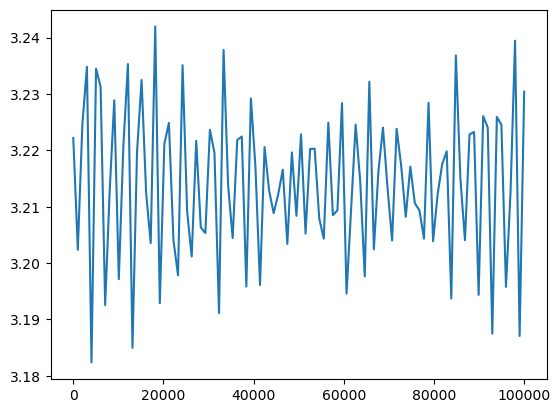

In [33]:
plt.plot(int_values[:]/(2*np.pi), part_values[:,0,6])

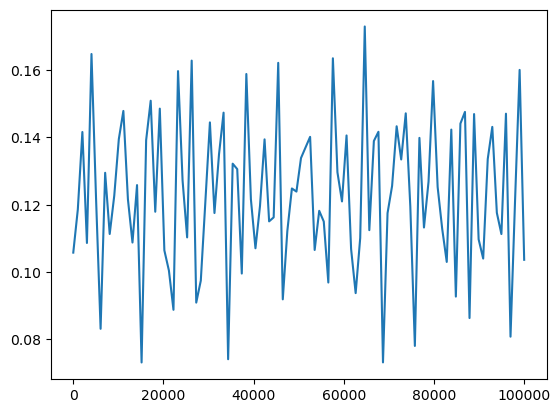

In [34]:
plt.plot(int_values[:]/(2*np.pi), part_values[:,0,7])

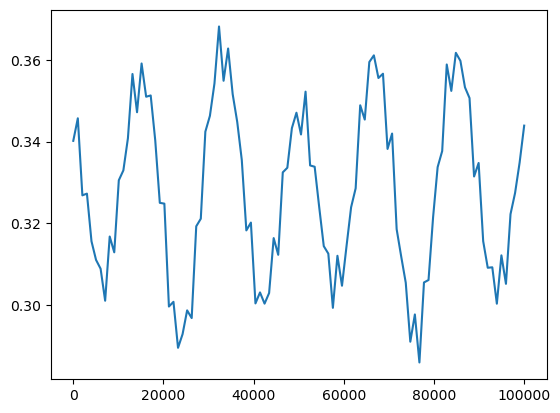

In [35]:
plt.plot(int_values[:]/(2*np.pi), part_values[:,0,8])

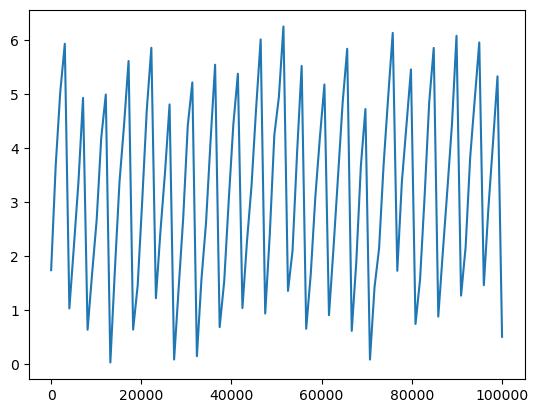

In [36]:
plt.plot(int_values[:]/(2*np.pi), part_values[:,0,9])

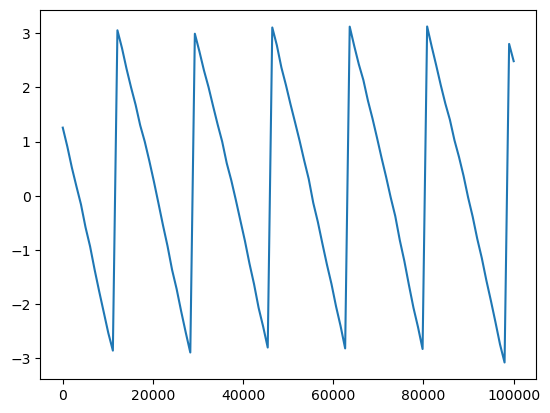

In [37]:
plt.plot(int_values[:]/(2*np.pi), part_values[:,0,10])

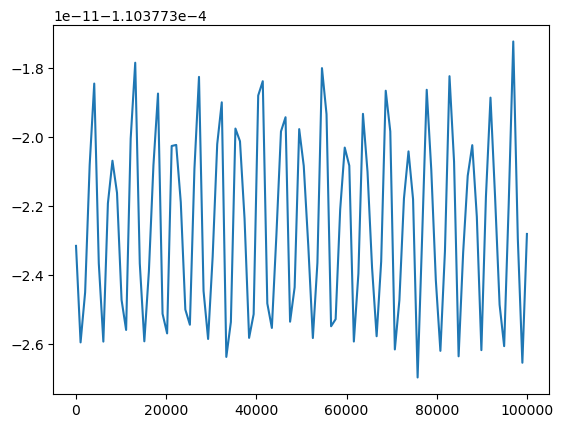

In [38]:
plt.plot(int_values[:]/(2*np.pi), sim_energy_values)